# Calculating Sheer and Veer from MetMasts
## Importing Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

## Reading In Dataset

In [2]:
# read in metmast dataset
metmasts = pd.read_parquet('../../data/cleaned/metmasts_data.parquet')

## Defining Shear

In [76]:
# defining the heights
speed_heights = {'mm_wind_speed_2': 40.0, 'mm_wind_speed_3': 60.0, 'mm_wind_speed_hh': 85.0}
direction_heights = {'mm_wind_direction_1': 20.0, 'mm_wind_direction_2': 40.0, 'mm_wind_direction_3': 60.0, 'mm_wind_direction_hh': 85.0}

# defining a minimum wind speed
min_wind_speed = 3.0

In [77]:
def wrap_diff(a, b):
    """Signed angular difference a - b in degrees, wrapped to [-180, 180)."""
    return (a - b + 180) % 360 - 180

In [78]:
def profile_slope(y, x):
    """Row-wise least-squares slope of y (n, k) against x (k,)."""
    xc = x - x.mean()
    yc = y - y.mean(axis = 1, keepdims = True)
    return (yc * xc).sum(axis = 1) / (xc ** 2).sum()

In [79]:
def shear_fit(df, heights):
    """Power-law shear exponent: slope of ln(speed) against ln(height)."""
    cols = sorted(heights, key = heights.get)
    x = np.log(np.array([heights[c] for c in cols], dtype = float))
    y = np.log(df[cols].to_numpy())
    return pd.Series(profile_slope(y, x), index = df.index)

In [80]:
def veer_fit(df, heights):
    """Veer in deg/100 m: slope of unwrapped direction against height."""
    cols = sorted(heights, key = heights.get)
    x = np.array([heights[c] for c in cols], dtype = float)
    theta = df[cols].to_numpy()
    ref = theta[:, [0]]                    
    y = ref + wrap_diff(theta, ref)          
    return pd.Series(profile_slope(y, x) * 100, index = df.index)

In [81]:
def valid_mask(df, heights_speed, heights_direction, min_ws = min_wind_speed):
    """All speeds above the threshold and all directions present."""
    ws = df[list(heights_speed)]
    wd = df[list(heights_direction)]
    return (ws > min_ws).all(axis = 1) & wd.notna().all(axis = 1)

In [82]:
def wind_analysis(df, heights_speed = speed_heights, heights_direction = direction_heights, min_ws = min_wind_speed):
    data = df[valid_mask(df, heights_speed, heights_direction, min_ws)].copy()
    data['shear'] = shear_fit(data, heights_speed)
    data['veer'] = veer_fit(data, heights_direction)
    return data

In [83]:
# running the function
metmasts_shear_veer = wind_analysis(metmasts)

In [84]:
# analyzing the shear column
metmasts_shear_veer['shear'].describe()

count    31797.000000
mean         0.008218
std          0.508904
min         -1.863841
25%         -0.281827
50%         -0.097199
75%          0.229986
max          2.284729
Name: shear, dtype: float64

In [85]:
# analyzing the veer column
metmasts_shear_veer['veer'].describe()

count    31797.000000
mean        -1.795953
std         22.098468
min       -317.457046
25%         -9.893897
50%         -1.573126
75%          9.973244
max        214.695969
Name: veer, dtype: float64

In [46]:
# looking into how much of the data is missing from the original dataset
1 - (metmasts_shear_veer.shape[0] / metmasts.shape[0])

0.19103953594871015

In [57]:
# looking at the very large values of veer
metmasts_shear_veer.sort_values('veer').head(10)

,utc,mm_wind_speed_1,mm_wind_speed_2,mm_wind_speed_3,mm_wind_speed_hh,mm_wind_direction_1,mm_wind_direction_2,mm_wind_direction_3,mm_wind_direction_hh,mm_pressure_bar_1,mm_pressure_bar_2,mm_rel_humidity_1,mm_rel_humidity_2,mm_temp_amb,shear,veer
3038,2026-01-22 10:20:00,NaN,4.235079,4.417778,3.015200,45.261970,180.556820,29.520000,243.969546,NaN,875.409454,-10.247353,77.603333,18.210000,-0.451129,-317.457046
11213,2026-03-20 04:50:00,NaN,3.570769,5.476984,3.020606,325.098027,108.642273,325.231818,213.208333,NaN,880.257647,-8.262121,77.378064,33.719999,-0.156307,-239.539769
6218,2026-02-13 12:20:00,NaN,4.556481,6.484559,4.821818,299.709710,104.753677,273.659129,220.672897,NaN,874.661726,-12.734348,77.890149,15.427778,0.133419,-214.102494
8220,2026-02-27 10:00:00,NaN,3.625224,5.055652,3.148000,295.302285,73.788841,286.312714,203.230571,NaN,879.675253,-10.342222,78.195263,26.585000,-0.136431,-211.845634
6210,2026-02-13 11:00:00,NaN,5.112453,5.938636,5.441493,285.196568,101.323134,270.583134,210.807463,NaN,874.782630,-12.598600,77.789538,16.169000,0.108329,-206.953657
6195,2026-02-13 08:30:00,NaN,4.357333,6.158116,3.922353,295.862610,113.897101,294.457102,219.198261,NaN,875.980196,-12.579302,78.124848,16.225000,-0.085773,-204.716523
13264,2026-04-03 10:40:00,NaN,3.656143,5.105072,3.252239,301.831142,112.257206,287.998289,229.061144,NaN,875.371769,-12.632187,76.830952,17.230000,-0.103766,-201.284456
9342,2026-03-07 05:00:00,NaN,3.942656,4.888437,3.456923,319.932878,66.281076,298.719696,230.958939,NaN,877.249385,-12.314583,78.308364,17.853333,-0.142424,-197.241598
6211,2026-02-13 11:10:00,NaN,5.105294,6.712836,4.475385,310.494330,114.798059,302.089404,242.242537,NaN,874.706327,-12.687407,77.668710,15.945000,-0.133201,-188.732018
12230,2026-03-27 06:20:00,NaN,5.876191,5.243538,3.145079,272.920606,204.979243,268.831077,126.789242,NaN,875.893245,-9.212647,76.725246,30.724000,-0.861036,-187.271130


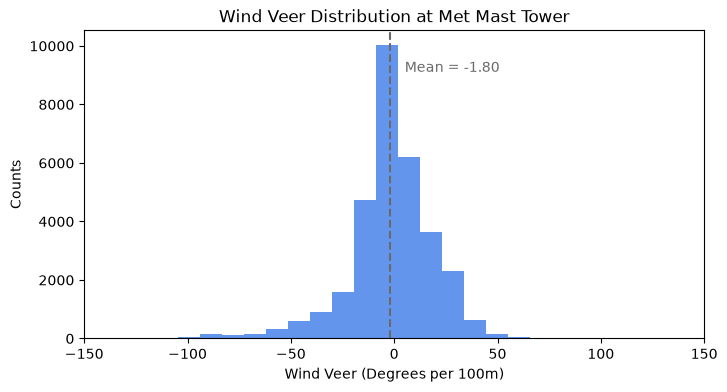

In [70]:
# defining the mean veer value
veer_mean = metmasts_shear_veer['veer'].mean()

# plotting the veer distribution
metmasts_shear_veer['veer'].plot.hist(bins = 50, color = 'cornflowerblue', figsize = (8, 4))
plt.axvline(veer_mean, color = 'dimgray', linestyle = '--')
plt.text(veer_mean + 5, plt.ylim()[1] * 0.9, f' Mean = {veer_mean:.2f}', color = 'dimgray', va = 'top')
plt.xlim(-150, 150)
plt.xlabel('Wind Veer (Degrees per 100m)')
plt.ylabel('Counts')
plt.title('Wind Veer Distribution at Met Mast Tower')
plt.show()

In [73]:
def veer_table(df, rename_map = None, n = None, decimals = 3):
    cols = ["mm_wind_direction_1", "mm_wind_direction_2", "mm_wind_direction_3", "mm_wind_direction_hh", "veer"]
    if rename_map is None:
        rename_map = {
            "mm_wind_direction_1": "Wind Direction Height 1 (degrees)",
            "mm_wind_direction_2": "Wind Direction Height 2 (degrees)",
            "mm_wind_direction_3": "Wind Direction Height 3 (degrees)",
            "mm_wind_direction_hh": "Wind Direction Height 4 (degrees)",
            "veer": "Veer (deg/100m)",
        }

    table = (
        df[cols]
        .sort_values("veer", ascending = True)
        .rename(columns = rename_map)
        .round(decimals)
        .reset_index(drop=True)
    )
    if n is not None:
        table = table.head(n)

    return table

In [75]:
veer_table(metmasts_shear_veer, n = 8)

,Wind Direction Height 1 (degrees),Wind Direction Height 2 (degrees),Wind Direction Height 3 (degrees),Wind Direction Height 4 (degrees),Veer (deg/100m)
0,45.262,180.557,29.520,243.970,-317.457
1,325.098,108.642,325.232,213.208,-239.540
2,299.710,104.754,273.659,220.673,-214.102
3,295.302,73.789,286.313,203.231,-211.846
4,285.197,101.323,270.583,210.807,-206.954
5,295.863,113.897,294.457,219.198,-204.717
6,301.831,112.257,287.998,229.061,-201.284
7,319.933,66.281,298.720,230.959,-197.242


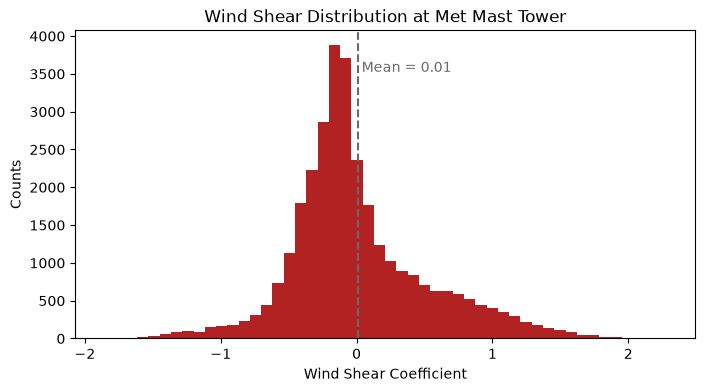

In [88]:
# defining the mean shear value
shear_mean = metmasts_shear_veer['shear'].mean()

# plotting the shear distribution
metmasts_shear_veer['shear'].plot.hist(bins = 50, color = 'firebrick', figsize = (8, 4))
plt.axvline(shear_mean, color = 'dimgray', linestyle = '--')
plt.text(shear_mean, plt.ylim()[1] * 0.9, f' Mean = {shear_mean:.2f}', color = 'dimgray', va = 'top')
plt.xlabel('Wind Shear Coefficient')
plt.ylabel('Counts')
plt.title('Wind Shear Distribution at Met Mast Tower')
plt.show()